# Solar and wind — demand and quantum-window studies

**Question:** How do renewable forecasts affect cost gaps and the choice of quantum hours?

Run the setup once, then choose a study. The original-vs-reduced comparison and the 4/5/6-hour search are independent. The expanded 1–24-hour search is the broader investigation; its final confirmation cell requires that search first. Each chosen hour still uses a separate reduced circuit.

- [Original vs reduced](#solar-wind-reduced-study)
- [4 / 5 / 6-hour search](#solar-wind-window-study)
- [All 300 contiguous windows and confirmation](#reduced-hourly-all-windows)

Renewables change thermal demand, not the number of binary plant decisions. Reserve remains based on gross demand. Each scenario is compared with its own matching MILP reference.

[Main method](../solution/reduced_qubit_hybrid_hourly.ipynb) · [Window selection](quantum_window_selection.ipynb) · [Solar + wind](solar_wind.ipynb) · [Other experiments](research_archive.ipynb)

Use the **qBraid-SDK kernel**. The setup cell resolves the project paths automatically. No other notebook needs to be run first. Existing outputs below were copied from the original starter; they are recorded results, not fresh executions of this split. The original studies are preserved in the [research archive](../experiments/research_archive.ipynb); no other notebook is a runtime dependency. End times are exclusive: **13:00–18:00 means hours 13, 14, 15, 16, 17**.


In [ ]:
# Resolve data and shared helpers when opening a notebook from its own folder.
from pathlib import Path
import os
import sys
PROJECT_ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
                     if (p / 'src/check.py').is_file() and (p / 'data').is_dir()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Open this notebook inside the cloned project.')
if str(PROJECT_ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / 'src'))
os.chdir(PROJECT_ROOT)


In [ ]:
from notebook_studies import study_context


<a id="solar-wind-reduced-study"></a>
## SOLAR + WIND — original vs reduced-qubit hybrid

**Run the setup, settings and run cells below.** It loads the shared RQ definitions itself; you do not need to rerun the earlier experiments. Results, tables, and four bar charts are saved here when this cell runs.

This applies reduced-qubit hourly scheduling to net demand after solar and wind generation. Ten thermal plants; solar and wind treated as forecast supply; original gross-demand reserve; 200 shots, one QAOA layer, six matched seeds. Every scenario has its own full-day MILP reference. The main QAOA period is **hours 13–17, excluding hour 18**. The highest net-load hours are a separate comparison, not a claim of the best window.

The earlier matched audit found mean gaps of **0.107% → 0.079%** (original → reduced) without renewables and **1.241% → 1.083%** with solar/wind. Reduced circuits used **11–13 qubits**, versus 13 originally. Renewables lowered the operating-cost baseline from about **$602,139 to $488,990**, even though the percentage gap increased. The fresh output below is the rerunnable evidence; invalid runs are displayed and excluded from cost averages.

After a kernel restart, rerun this study to recreate `solar_wind_rq_study` in memory.


In [ ]:
solar_comparison = study_context(
    SW_SEEDS=(7, 8, 9, 17, 18, 19), SW_HOURS=tuple(range(13, 18)), SW_SHOTS=200,
)


SOLAR + WIND — matched 10-plant comparison; local simulation only
Seeds (7, 8, 9, 17, 18, 19); 200 shots, p=1, 3 slack bits.
Primary hours [13, 14, 15, 16, 17]; top net-load hours [11, 12, 13, 14, 15].
Renewable energy share 16.48%; reserve unchanged; no curtailment.
Each scenario uses its OWN full-day MILP reference. Invalid runs never enter gap averages.


No renewables / 13–17, seed 7: comparisons complete


No renewables / 13–17, seed 8: comparisons complete


No renewables / 13–17, seed 9: comparisons complete


No renewables / 13–17, seed 17: comparisons complete


No renewables / 13–17, seed 18: comparisons complete


... (10 outputs left out)

Solar + wind / top net hours, seed 17: comparisons complete


Solar + wind / top net hours, seed 18: comparisons complete


Solar + wind / top net hours, seed 19: comparisons complete


scenario,method,valid_days,milp_cost,mean_valid_gap_pct,mean_valid_cost,mean_extra_dollars,min_qubits,max_qubits,mean_qubits,median_total_s,quantum_job_credits
No renewables / 13–17,Full-day MILP,6/6,602139.4700,0.0000,602139.4700,0.0000,0,0,0,0.0806,0
No renewables / 13–17,Original hybrid,6/6,602139.4700,0.1071,602784.4950,645.0250,13,13,13.0000,3.3401,0
No renewables / 13–17,Reduced hybrid,6/6,602139.4700,0.0785,602612.3283,472.8583,11,13,11.6333,2.0232,0
Solar + wind / 13–17,Full-day MILP,6/6,488990.4067,0.0000,488990.4067,0.0000,0,0,0,0.0803,0
Solar + wind / 13–17,Original hybrid,6/6,488990.4067,1.2407,495057.2216,6066.8150,13,13,13.0000,3.2328,0
Solar + wind / 13–17,Reduced hybrid,6/6,488990.4067,1.0834,494287.9174,5297.5107,11,13,12.0000,2.0601,0
Solar + wind / top net hours,Full-day MILP,6/6,488990.4067,0.0000,488990.4067,0.0000,0,0,0,0.0801,0
Solar + wind / top net hours,Original hybrid,6/6,488990.4067,1.3918,495796.3286,6805.9220,13,13,13.0000,3.1255,0
Solar + wind / top net hours,Reduced hybrid,6/6,488990.4067,1.2087,494900.7892,5910.3826,11,12,11.3333,2.0685,0


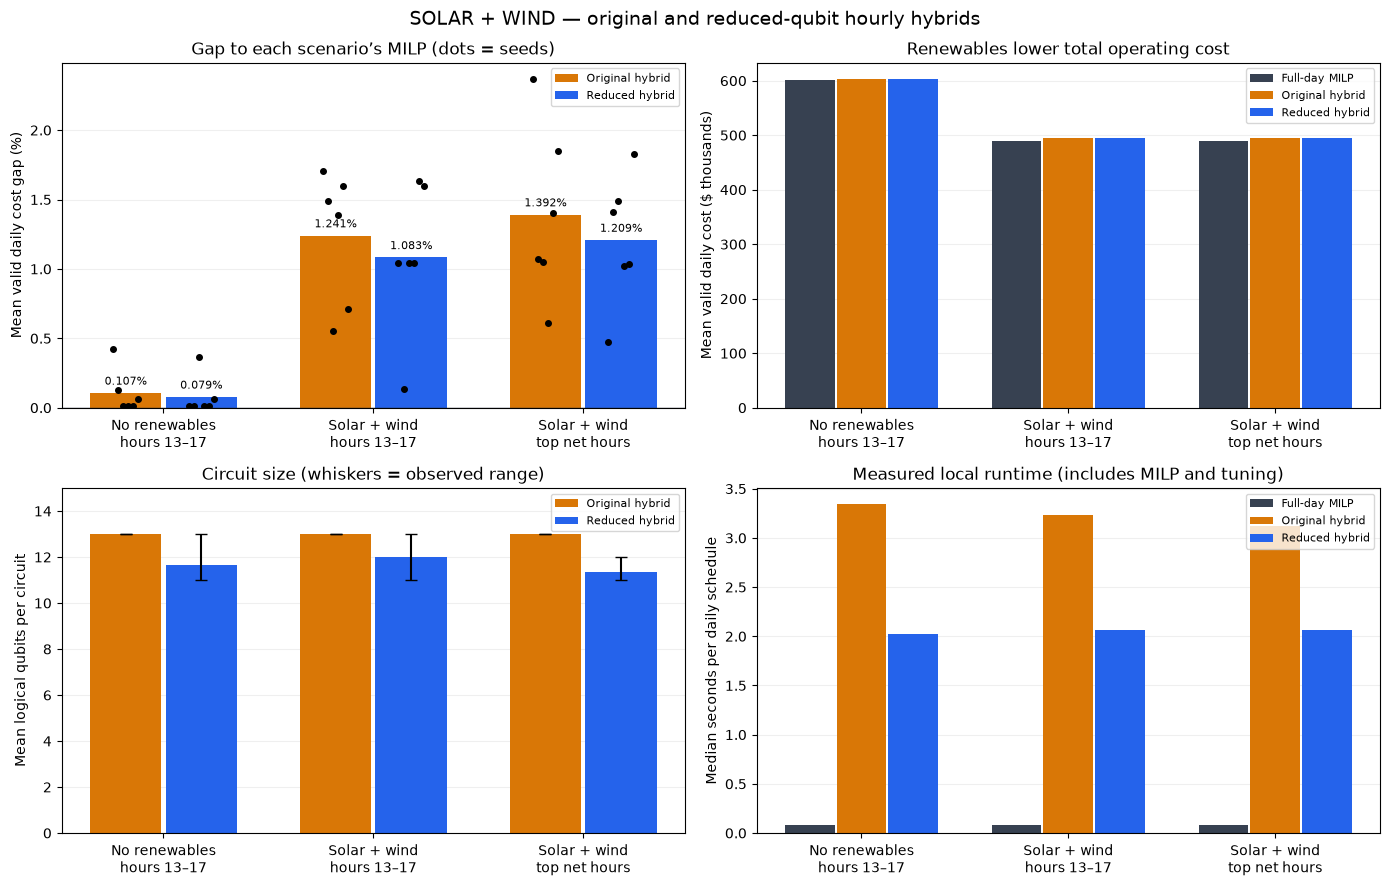

Interpretation: smaller circuits do not guarantee smaller scheduling gaps. Compare dollars AND percentages.
Top net-load hours are a heuristic, not a proven best window. One forecast day and six seeds do not establish generality.
No QPU jobs submitted. Quantum-job credits = 0; subscription/AI charges are not allocated here.
Existing limits remain: approximate hourly QUBO, 3 slack bits, no ramp/forecast-error constraints in this experiment.


In [ ]:
solar_wind_rq_study = solar_comparison['run_solar_wind_rq_study']()


<a id="solar-wind-window-study"></a>
## SOLAR + WIND — 4 / 5 / 6 HOUR WINDOW STUDY

**Run the setup, settings and run cells below.** It imports shared RQ definitions into an isolated namespace; no earlier experiment or hardware cell needs to execute. This study can take several minutes on the local CPU. Tables and four charts are saved as cell outputs.

**Question:** With solar and wind, which hours should receive our existing reduced-qubit hourly QAOA? All **60 contiguous 4-, 5-, and 6-hour windows** within hours 0–23 are screened on seeds 7, 8, 9. The top three all-valid windows of each length are fixed before validation on **eight fresh seeds, 101–108**. The current **13:00–18:00** window and the previous top-net-load window are retained as controls. Each selected hour still uses a separate circuit. End times are exclusive.

All methods use ten thermal plants, identical forecasts, the original gross-demand reserve, p=1, 200 shots/hour, three slack bits, and the **same renewable MILP baseline**. Gap = `100 × (hybrid cost − MILP cost) / MILP cost`. Invalid runs remain visible and cannot qualify as screening winners. Every reduced QUBO is audited and every reported valid schedule is checked. Finalists are rerun without screening's exact tuning cache; validation timings also disable it.

**How to interpret:** Compare windows of the same length first; fewer QAOA hours means a different quantum-job budget. “Best” is an empirical result on this forecast day, not proof for other days or arbitrary scattered hour combinations. Validation seeds test sampling variability, not weather/forecast variability. Selecting again based on validation scores would require another independent test.

**Separate concepts:** “Remaining-day lookahead” means hours after a current decision through hour 23 (e.g. after hour 13: hours 14–23). The experimental future-cost scoring method is **not included here**; this cell tests only the current reduced-qubit hybrid's choice of QAOA hours.


**Recorded results — completed sweep and fresh-seed validation**

All 60 windows were screened. Ten finalists/controls were validated on eight fresh seeds; all were valid in 8/8 runs. The study executed **298 schedules**, including 30 exact uncached reproduction checks and eight MILP baseline repeats. All 298 passed the existing physical checks; all reduced-QUBO audits passed.

| Candidate | Duration | Fresh-seed mean gap | Worst fresh-seed gap | Qubits/circuit | Median local runtime |
|---|---:|---:|---:|---:|---:|
| 15:00–19:00 | 4 h | 0.306% | 0.696% | 11–13 | 1.71 s |
| 15:00–20:00 | 5 h | 0.414% | 0.709% | 11–13 | 2.07 s |
| 15:00–21:00 | 6 h | 0.725% | 1.126% | 11–13 | 2.38 s |
| 13:00–18:00 (current control) | 5 h | 0.737% | 1.472% | 11–13 | 2.06 s |

**Best supported candidate here: 15:00–19:00**, meaning QAOA in hours **15, 16, 17, 18**, and MILP in the other hours. It was selected before validation and also had the lowest validation mean among the ten finalists. It improved over the current 13:00–18:00 window in five paired validation seeds, tied in one, and worsened in two: this is an average improvement, not an every-run guarantee.

For an equal five-hour quantum budget, **15:00–20:00** improved the fresh-seed mean from **0.737% to 0.414%**. Four-hour results use fewer QAOA jobs/shots, so compare that tradeoff explicitly. The control differs from the previous 1.083% result because this validation uses **new seeds 101–108**. All costs still use the same renewable MILP reference, **$488,990.41**. Full MILP remains the zero-gap reference and was approximately 0.10 s.

These windows were tested on one forecast day; other days require independent validation. Rerun the study to recreate `solar_wind_window_study`.


In [ ]:
short_windows = study_context(
    WW_LENGTHS=(4, 5, 6), WW_SELECTION_SEEDS=(7, 8, 9),
    WW_VALIDATION_SEEDS=tuple(range(101, 109)), WW_TOP_PER_LENGTH=3,
    WW_SHOTS=200, WW_SCREEN_CACHE=True,
)


SOLAR + WIND — exhaustive contiguous 4/5/6-hour window study
10 plants; p=1; 200 shots/hour; own full-day MILP $488,990.41.
Solar/wind are fixed forecasts; reserve stays based on gross demand. Existing reduced-qubit method only.
Screen 60 windows on seeds (7, 8, 9); validate top 3 per length on (101, 102, 103, 104, 105, 106, 107, 108).
Only all-valid windows qualify. Invalid runs remain visible; invalid costs never enter gap means.


Screen 01/60: 4h 00:00–04:00, valid 3/3, mean gap 6.1534%


Screen 02/60: 4h 01:00–05:00, valid 3/3, mean gap 6.0854%


Screen 03/60: 4h 02:00–06:00, valid 3/3, mean gap 6.0093%


Screen 04/60: 4h 03:00–07:00, valid 3/3, mean gap 6.4515%


Screen 05/60: 4h 04:00–08:00, valid 3/3, mean gap 5.5181%


... (80 outputs left out)

phase,window,start,length,valid_days,runs,mean_valid_gap_pct,worst_valid_gap_pct,mean_valid_cost,min_qubits,max_qubits,median_total_s,timing_cached,selection_winner
validation,15:00–19:00,15,4,8,8,0.3058,0.6959,490485.9121,11,13,1.7071,False,True
validation,12:00–16:00,12,4,8,8,0.6244,1.4501,492043.8100,11,12,1.6783,False,False
validation,13:00–17:00,13,4,8,8,0.4948,1.0191,491409.7135,11,12,1.6578,False,False
validation,15:00–20:00,15,5,8,8,0.4144,0.7085,491016.7531,11,13,2.0688,False,True
validation,13:00–18:00,13,5,8,8,0.7373,1.4716,492595.7414,11,13,2.0632,False,False
validation,14:00–19:00,14,5,8,8,0.5912,1.3870,491881.3267,11,13,1.8380,False,False
validation,15:00–21:00,15,6,8,8,0.7254,1.1261,492537.6866,11,13,2.3789,False,True
validation,14:00–20:00,14,6,8,8,0.8159,1.8571,492980.2309,11,13,2.2290,False,False
validation,13:00–19:00,13,6,8,8,1.3792,2.3622,495734.7069,11,13,2.2732,False,False
validation,11:00–16:00,11,5,8,8,0.8654,1.9288,493222.0545,10,12,2.0834,False,False



PRESELECTED WINNERS — each chosen using screening seeds only


phase,window,start,length,valid_days,runs,mean_valid_gap_pct,worst_valid_gap_pct,mean_valid_cost,min_qubits,max_qubits,median_total_s,timing_cached,selection_winner
validation,15:00–19:00,15,4,8,8,0.3058,0.6959,490485.9121,11,13,1.7071,False,True
validation,15:00–20:00,15,5,8,8,0.4144,0.7085,491016.7531,11,13,2.0688,False,True
validation,15:00–21:00,15,6,8,8,0.7254,1.1261,492537.6866,11,13,2.3789,False,True


window,length,seed,candidate_valid,original_valid,gap_change_percentage_points
15:00–19:00,4,101,True,True,0.1221
15:00–19:00,4,102,True,True,-0.5472
15:00–19:00,4,103,True,True,0.0000
15:00–19:00,4,104,True,True,-1.3188
15:00–19:00,4,105,True,True,-0.5277
15:00–19:00,4,106,True,True,0.0804
15:00–19:00,4,107,True,True,-0.5738
15:00–19:00,4,108,True,True,-0.6868
15:00–20:00,5,101,True,True,0.1348
15:00–20:00,5,102,True,True,-0.5472


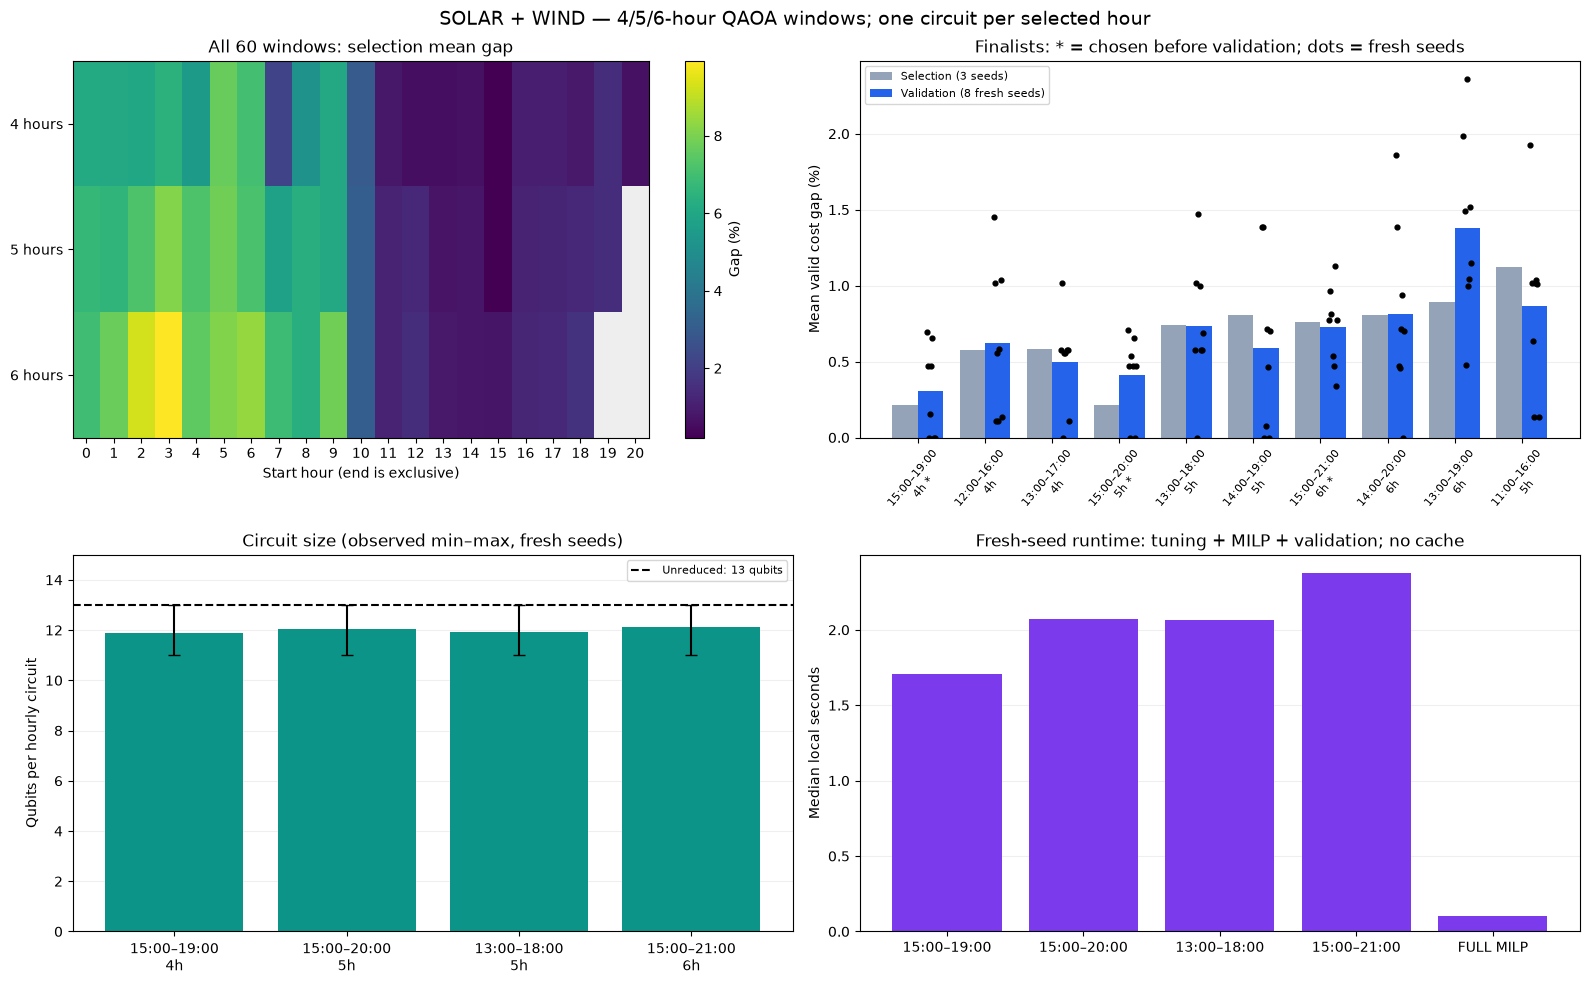

All reduced-QUBO substitutions audited. Valid schedules passed demand, reserve and min up/down checks.
Best means best among tested contiguous windows on this day; not proof across other days or arbitrary hour subsets.
Compare within the same duration first: a 4-hour window uses fewer QAOA jobs/shots than a 6-hour window.
The separate future-cost prototype is NOT included. Existing MILP stretches already plan through the remaining day.
Quantum-job credits spent: 0 (local ideal simulation). No hardware/noise or quantum speed advantage measured.
Screening tuning reuse: {'hits': 308, 'misses': 586} ; finalist schedules reproduced exactly without caching.
Total study time 479.5 s; 298 schedule runs plus the reference/curtailment checks.


In [ ]:
solar_wind_window_study = short_windows['run_solar_wind_window_study']()


<a id="reduced-hourly-all-windows"></a>
## REDUCED QUBIT HYBRID HOURLY METHOD — ALL 1–24 HOUR WINDOWS

**This is the expanded window search.** The earlier 4/5/6-hour study was only a restricted comparison. Here we screen **every nonempty contiguous window inside the day: 300 candidates**, including all 24 individual hours and **full-day QAOA as 24 separate hourly circuits**. No multihour circuit is introduced. “Window length” is the number of hours assigned to quantum; it does not multiply the qubits per circuit.

**Run:** execute the setup, settings and run cells below. It imports shared RQ definitions and loads renewable data, without running other experiments or submitting cloud jobs. Ten thermal plants, solar/wind net load, gross-demand reserve, p=1, three slack bits, and 200 shots per selected hour are held fixed.

**Selection:** screen all 300 windows on seeds 7, 8, 9. Before validation, freeze the all-valid winner for each duration, five leading overall candidates, and explicit controls (the previous settings and full-day hourly QAOA). Validate those choices on **fresh seeds 201–208**. Select the overall cost-gap candidate by mean gap, worst gap, fewer quantum hours, then earlier start. End times are exclusive. Invalid runs remain visible and cannot qualify as winners.

**Compute and correctness:** exact deterministic angle-tuning reuse makes the broad search practical; it never reuses sampled choices or schedules. Every schedule is freshly sampled with matched seeds and checked, and every reduced QUBO is audited. Separate uncached repeats of short/medium/full-day cases must reproduce the same schedules; only their timings are presented as standalone runtimes. This does not change the scheduling algorithm.

**Interpretation:** the lowest-cost-gap window may contain just one hour, leaving 23 hours to MILP. Therefore also inspect the best window at every duration and the quantum-hours/cost-gap tradeoff. MILP remains the zero-gap reference. A low gap does not establish quantum advantage. “Best” applies to the tested contiguous windows and this forecast day, not arbitrary scattered hour subsets or other days. The future-cost scoring prototype remains separate.


**Focused confirmation:** because the leading short-window means were close, the cell also freezes the three best all-valid validation candidates plus the old window, then tests them on **16 further fresh seeds, 301–316**. This final comparison runs without tuning reuse and is stored in `reduced_qubit_hybrid_hourly_window_study["confirmation"]`.


**Recorded final findings — complete all-duration search**

All **300 contiguous windows** were screened (900 runs). **28 finalists/controls** were validated on eight fresh seeds (224 runs), with nine uncached reproduction checks and eight MILP repeats. The leading three short windows and the old control were then confirmed on **16 further seeds** (64 runs). All **1,205 recorded schedule executions** passed the existing model’s physical checks. Repeated benchmarks are not extra independent seed evidence.

**Best supported cost-gap choice: 16:00–17:00.** QAOA runs only in planning hour **16**, in one reduced circuit; MILP handles the other 23 hours. This had the lowest mean of the finalists in the first validation and again in the separate confirmation. It is an empirical recommendation for this forecast day, not proof of a unique optimum for every seed or day.

| Window | Quantum hours | Confirmation valid runs | Mean gap | Worst gap | Qubits/circuit | Median local runtime |
|---|---:|---:|---:|---:|---:|---:|
| 16:00–17:00 | 1 | 16/16 | 0.122% | 0.548% | 12 | 1.35 s |
| 14:00–15:00 | 1 | 16/16 | 0.204% | 0.938% | 11 | 1.02 s |
| 15:00–16:00 | 1 | 16/16 | 0.205% | 0.939% | 11 | 1.01 s |
| 13:00–18:00 | 5 | 16/16 | 1.088% | 2.526% | 11–13 | 2.03 s |

These four rows use the **same 16 confirmation seeds, 301–316**, with no tuning cache. The 16:00–17:00 window beat the old 13:00–18:00 control in every paired confirmation seed. It uses fewer quantum hours, so this is a tradeoff in quantum work as well as a change in timing. If an **11-qubit circuit limit** is the priority, 14:00–15:00 or 15:00–16:00 is an alternative; the lowest observed cost-gap choice uses **12 qubits**.

**Full-day hourly QAOA was tested:** 24 separate circuits, valid 8/8, mean gap **18.285%** on the eight validation seeds 201–208. It was not one large circuit. On those same eight seeds, the preselected four-hour window 15:00–19:00 averaged **0.474%**, and the five-hour 15:00–20:00 window averaged **0.747%**. These are a different seed bank from the confirmation table above.

MILP remains the **$488,990.41** zero-gap reference and was about **0.08 s** locally. A near-zero hybrid gap does not establish quantum speedup: MILP still does most of the scheduling in a one-hour hybrid. All code, tables, and eight chart panels are saved below; rerun the cell to recreate `reduced_qubit_hybrid_hourly_window_study` and its `confirmation` data.


In [ ]:
all_windows = study_context(
    AW_LENGTHS=tuple(range(1, 25)), AW_SELECTION_SEEDS=(7, 8, 9),
    AW_VALIDATION_SEEDS=tuple(range(201, 209)), AW_TOP_OVERALL=5,
    AW_SHOTS=200, AW_TUNING_CACHE=True,
)


REDUCED QUBIT HYBRID HOURLY METHOD — ALL 300 CONTIGUOUS WINDOWS
10 plants with solar/wind; p=1; 200 shots per selected hour; MILP reference $488,990.41.
One circuit per selected hour, even for the full-day 24-hour candidate.
Screening seeds (7, 8, 9); fresh validation seeds (201, 202, 203, 204, 205, 206, 207, 208).
A window must be valid in every screening seed to qualify as a winner. Failures remain visible.


Screen 10/300: 00:00–10:00 (10 hourly circuits), valid 3/3, gap 12.1746%


Screen 20/300: 00:00–20:00 (20 hourly circuits), valid 3/3, gap 17.2426%


Screen 24/300: 00:00–24:00 (24 hourly circuits), valid 3/3, gap 17.8983%


Screen 30/300: 01:00–07:00 (6 hourly circuits), valid 3/3, gap 7.7213%


Screen 40/300: 01:00–17:00 (16 hourly circuits), valid 3/3, gap 15.5812%


... (66 outputs left out)


PRESELECTED OVERALL COST-GAP CHOICE, evaluated on fresh seeds:


phase,window,start,length,valid_days,runs,mean_valid_gap_pct,worst_valid_gap_pct,mean_valid_cost,min_qubits,max_qubits,median_total_s,timing_cached,selection_winner,overall_preselected
validation,14:00–15:00,14,1,8,8,0.0583,0.4662,489275.3669,11,11,0.2913,True,True,True



EXPLORATORY: most quantum hours among validated candidates below stated mean-gap thresholds


mean_gap_threshold_pct,window,quantum_hours,mean_valid_gap_pct
0.1000,16:00–17:00,1,0.0477
0.5000,15:00–19:00,4,0.4740
1.0000,15:00–20:00,5,0.7467


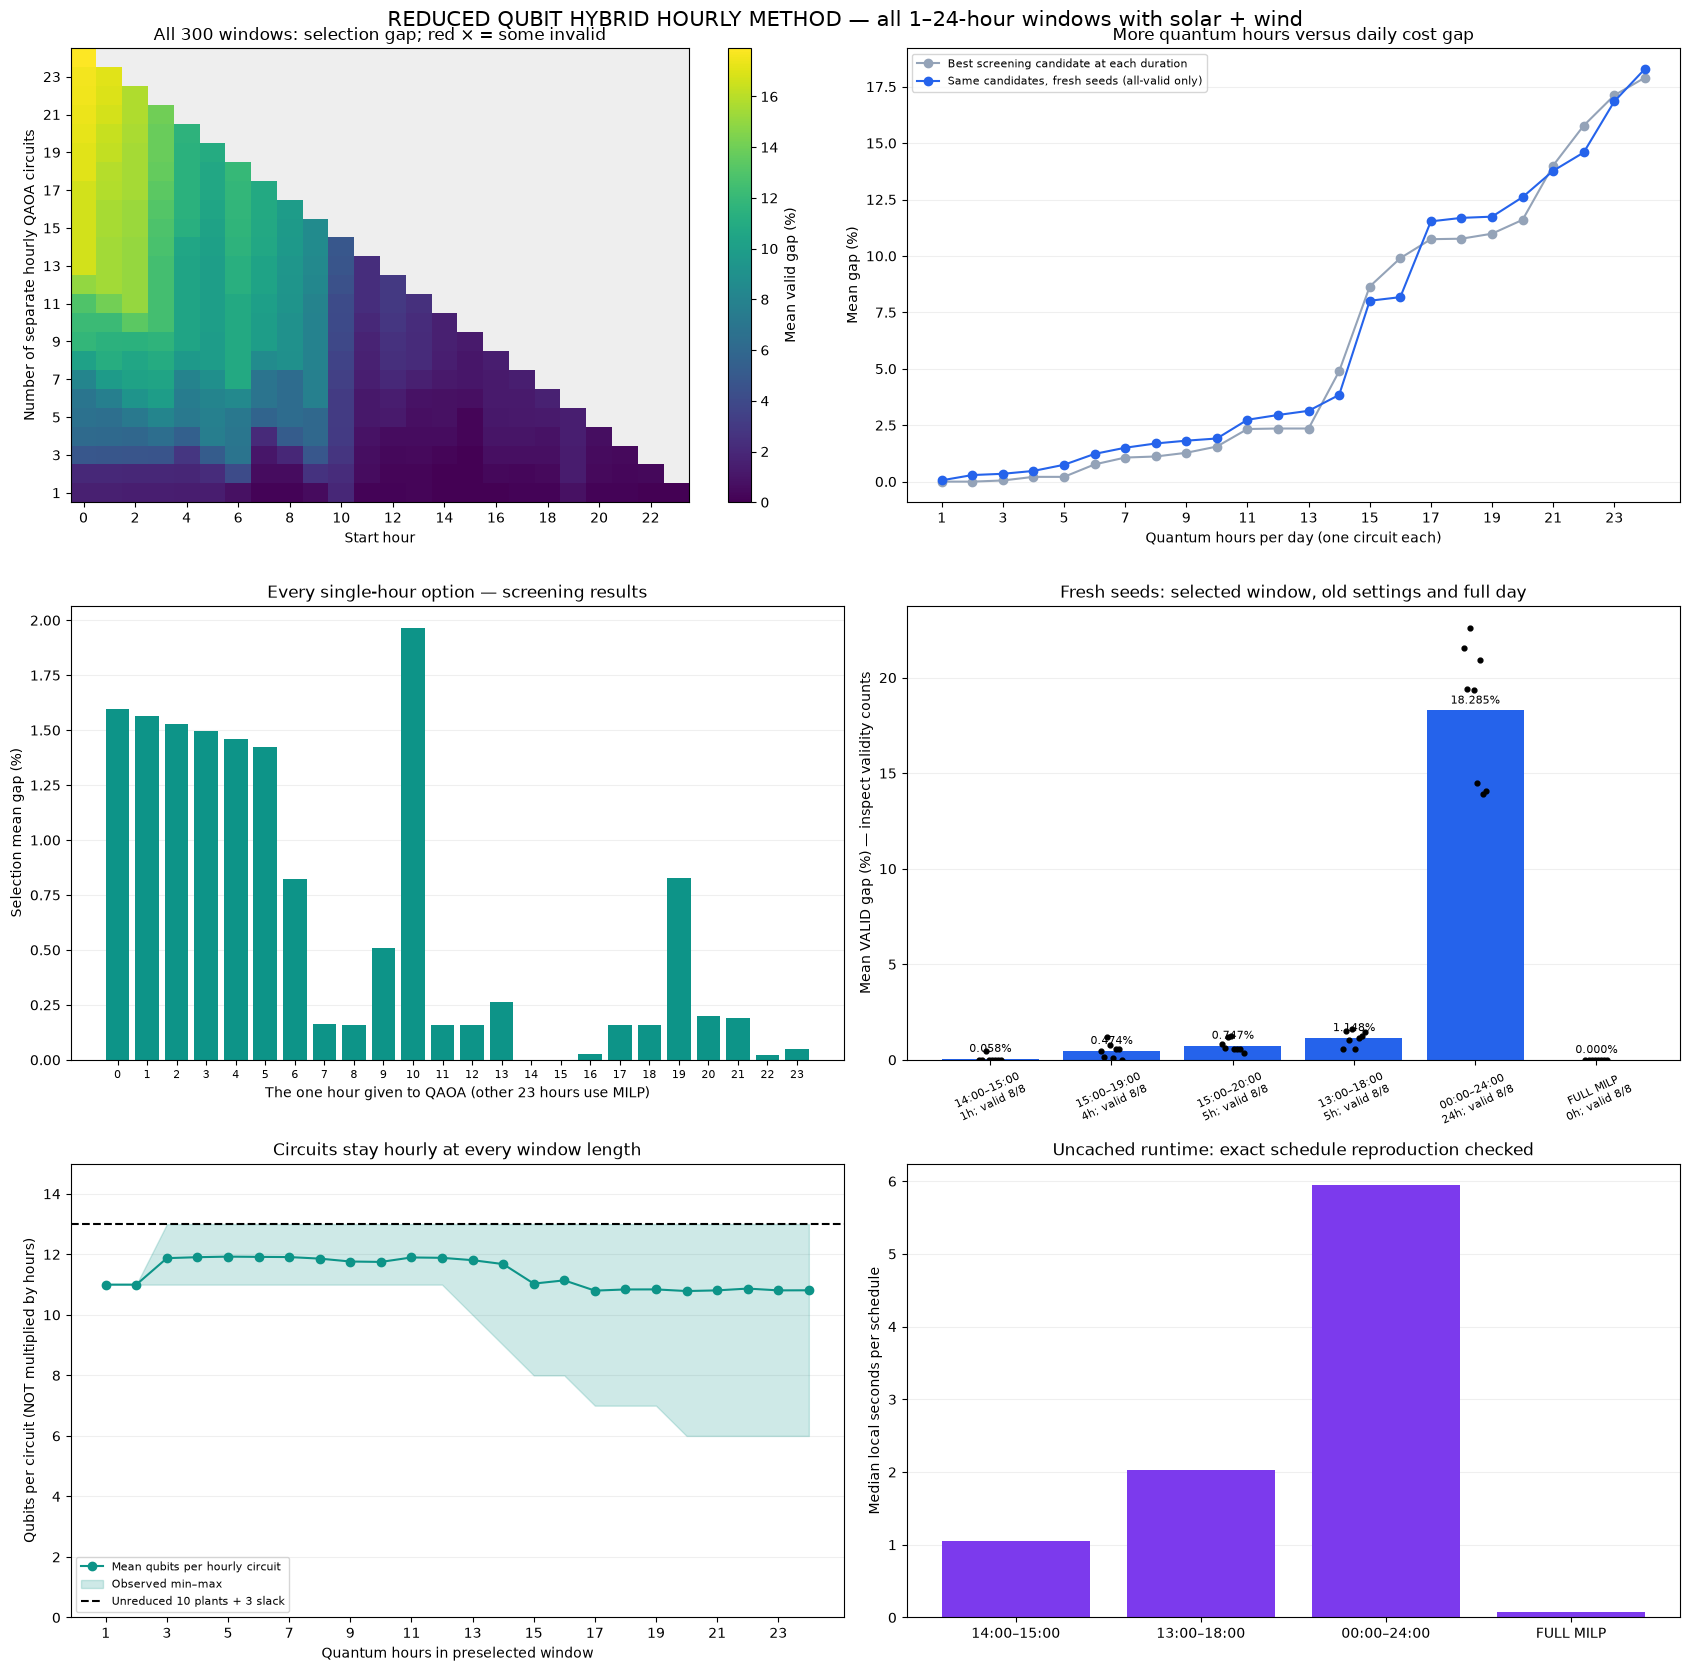

Best COST gap is not proof of quantum advantage: MILP is the zero-gap baseline; few QAOA hours leave most work to MILP.
The all-day case is 24 sequential hourly circuits, NOT one 24-hour circuit.
All 300 contiguous windows were screened; arbitrary scattered subsets and other forecast days are outside this study.
Same constraints/objective as before: gross-demand reserve, min up/down locks, approximate QUBO, no added forecast uncertainty or ramps.
Every reduced QUBO passed energy-equivalence auditing. Invalid days are not accepted as low-cost results.
The future-cost scoring prototype remains separate. Quantum-job credits spent: 0 (local simulation only).
Tuning reuse statistics: {'hits': 7746, 'misses': 2518} ; cold benchmark schedules matched cached results exactly.
Total study time 1127.5 s; 1141 schedule executions plus reference/curtailment checks.


FINAL CONFIRMATION — candidates fixed from the earlier validation results: [(16, 1), (14, 1), (15, 1), (13, 5)]
New seeds: (301, 302, 303, 304, 305, 306, 307, 308, 309, 310, 311, 312, 313, 314, 315, 316) ; no tuning cache; same forecast, constraints, shots and reduced-hourly algorithm.


Confirm 16:00–17:00: valid 16/16, mean gap 0.12190039760855216


Confirm 14:00–15:00: valid 16/16, mean gap 0.20432011460876368


Confirm 15:00–16:00: valid 16/16, mean gap 0.20453013615247384


Confirm 13:00–18:00: valid 16/16, mean gap 1.0880469072282322


window,start,length,valid_days,runs,mean_valid_gap_pct,worst_valid_gap_pct,mean_valid_cost,min_qubits,max_qubits,median_total_s
16:00–17:00,16,1,16,16,0.1219,0.5483,489586.4879,12,12,1.3497
14:00–15:00,14,1,16,16,0.2043,0.9381,489989.5124,11,11,1.0217
15:00–16:00,15,1,16,16,0.2045,0.9387,489990.5394,11,11,1.0066
13:00–18:00,13,5,16,16,1.0880,2.5264,494310.8517,11,13,2.0346


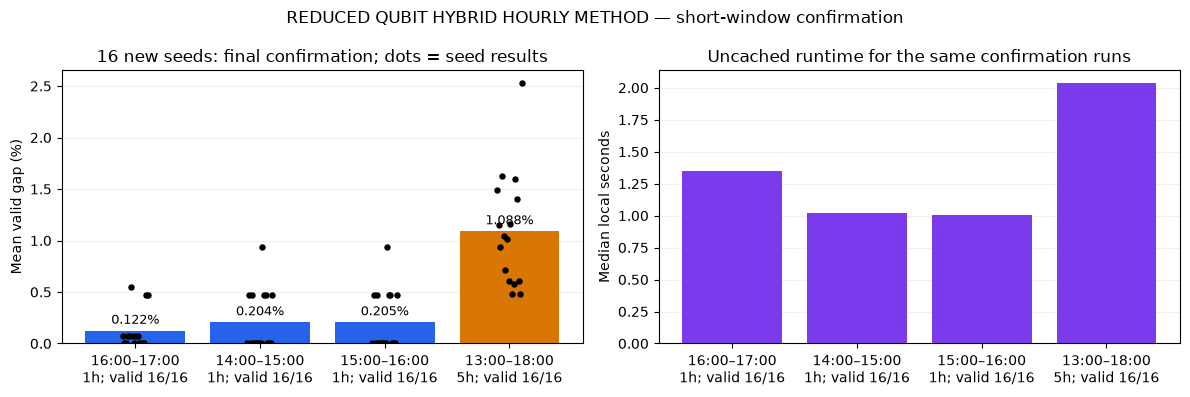

These are measured seed averages on one forecast day, not proof of a unique optimal window for every run/day.


In [ ]:
reduced_qubit_hybrid_hourly_window_study = all_windows['run_reduced_qubit_hybrid_hourly_window_study']()

# Third, disjoint seed bank; no tuning cache in these confirmation runs.
reduced_qubit_hybrid_hourly_window_study['confirmation'] = all_windows['confirm_reduced_qubit_hybrid_hourly_windows'](
    reduced_qubit_hybrid_hourly_window_study, seeds=tuple(range(301, 317)),
)
